# Escala dinámica31: cómo conservar una SD representable
## Pregunta y resumen
Continuamos Welford29 y escala externa30: ¿podemos adaptar unidades online sin inspeccionar datos futuros? Benchmark sintético45casos, contra Decimal100, y casos adversos. No se propone un nuevo estimador. NumPy escalado conserva ventaja temporal.
## Teoría y derivación
# Escala dinámica: identidad, unidades y límites
Sea x en unidades U, n entero, e un exponente entero y y=x/2^e sin unidades. El núcleo Welford desplazado29 conserva origen a, media relativa b y M2=Σ(y−ȳ)². Su recurrencia conocida es δ=(y−a)−b, b'=b+δ/(n+1), M2'=M2+δ((y−a)−b'). No proponemos una fórmula estadística inédita.

La limitación30 era necesitar e externo y rechazar un flujo con escalas muy distintas. Proponemos seleccionar e_t=max_{i≤t,x_i≠0} frexp(x_i).exponent; ceros iniciales no fijan escala. Así |y_i|≤1 para el máximo observado. Cuando llega una escala mayor e', definimos c=2^(e−e')≤1. Paso1: y'_i=cy_i. Paso2: a'=ca y b'=cb por linealidad de la media. Paso3: cada diferencia centrada se multiplica por c; entonces M2'=c²M2. Paso4: insertar el nuevo y con el núcleo existente. Esto justifica `ldexp(origin,shift)`, `ldexp(mean_offset,shift)`, `ldexp(m2,2*shift)` en `DynamicMoments.push`.

$$a'=2^{e-e'}a,\quad b'=2^{e-e'}b,\quad M_2'=2^{2(e-e')}M_2.$$
$$V_d=2^{2e}\frac{M_2}{n-d},\qquad SD_d=2^e\sqrt{M_2/(n-d)},\quad d\in\{0,1\},\ n>d.$$
Varianza tiene unidades U²; SD U; conteo, e, y y M2 normalizado sin unidades. Estas identidades son exactas en reales; no constituyen cota de error en máquina. El estado ocupa un número constante de escalares, procesa una pasada; no promete merge entre escalas (API sin merge). No cambian `Moments` ni `scaled_moments`.

Dominio finito binary64, n pequeño frente a2^53. Escala seleccionada puede ser1024 (frexp del mayor finito); no materializamos2^e, sino ldexp. En estado normalizado no hay grandes diferencias; no prueba estabilidad universal. Escalado binario exacto mientras representable: al reescalar puede perderse M2 diminuto o un dato bajo el mínimo subnormal. `rounded_to_zero` cuenta tales componentes/observaciones detectadas; no es cota ni conteo de toda información perdida. Cuantización sin llegar a cero sigue posible.

Casos límite: cero/constante→SD0; n≤d error; NaN/inf error; SD no representable→std_underflow/std_overflow; varianza no representable pero SD sí→variance_underflow/variance_overflow. Flujo [0,minsubnormal] tiene SD exacta minsubnormal/2 y redondea0: la salida se abstiene, no inventa éxito. [-minsubnormal,minsubnormal] SD=minsubnormal. Datos redondeados antes de entrada no se recuperan. Bajo orden adverso se acepta redondeo dependiente del orden; no afirmar asociatividad exacta. Sin parámetros aprendidos ni evidencia empírica.


In [1]:
import math,json,csv
from pathlib import Path
from src.dynamic import DynamicMoments,dynamic_moments
from src.benchmark_dynamic import oracle
from src.scaled import scaled_moments
from IPython.display import display,Image
print(json.loads(Path('config_dynamic.json').read_text()))

{'seeds': [31, 32, 33], 'n': 128, 'exponents': [-1070, -700, 0, 700, 1020], 'repeats': 5, 'dataset': 'synthetic uniform; floats received are oracle input', 'source': 'numpy default_rng', 'gate': 'relative SD error <=1e-12 on configured fixtures; subnormal tolerance separately tested <=4 ulp'}


## Traza: el cambio de unidades conserva el problema
Mostramos exponente y M2 normalizado después de cada ingreso. La contribución minúscula puede desaparecer al subir la escala: el contador lo expone sin prometer detectar todos los errores.

In [2]:
state=DynamicMoments()
for x in [1e-300,2e-300,1e300]:
    state=state.push(x)
    print(x,state.exponent,state.state.m2,state.rescales,state.rounded_to_zero)
assert state.rounded_to_zero>0
print('SD/1e300',state.result().std/1e300,'oracle',oracle([1e-300,2e-300,1e300])/1e300)

1e-300 -996 0.0 0 0
2e-300 -995 0.05606106910518821 1 0
1e+300 997 0.3716185521586013 2 3
SD/1e300 0.4714045207910317 oracle 0.4714045207910317


## Casos límite y abstención
La SD puede caber cuando V no cabe. En el mínimo subnormal, error relativo es una métrica engañosa: comprobamos también4ulp. Si SD real redondea0 se devuelve estado explícito.

In [3]:
tiny=math.ulp(0.)
for xs in [[-tiny,tiny],[0.,tiny],[1e200,2e200],[1e-200,2e-200]]:
    print(xs,dynamic_moments(xs))
assert dynamic_moments([-tiny,tiny]).std==tiny
assert dynamic_moments([0.,tiny]).status=='std_underflow'
assert dynamic_moments([1e200,2e200]).status=='variance_overflow'

[-5e-324, 5e-324] ScaleResult(n=2, exponent=-1073, status='variance_underflow', variance=0.0, std=5e-324)
[0.0, 5e-324] ScaleResult(n=2, exponent=-1073, status='std_underflow', variance=None, std=None)
[1e+200, 2e+200] ScaleResult(n=2, exponent=666, status='variance_overflow', variance=None, std=5e+199)
[1e-200, 2e-200] ScaleResult(n=2, exponent=-663, status='variance_underflow', variance=0.0, std=5e-201)


## Experimento reproducible y contraste justo
3seeds×5exponentes×3órdenes,128observaciones,5repeticiones por medición; oráculo Decimal100 sobre float recibido, no decimal ideal. NumPy escalado puede examinar datos completos primero; se mide su normalización, pero no obtiene restricción de una pasada. Comparación útil, no hardware optimizado equivalente. Escala externa0 es ablación de mala configuración, no baseline usado para afirmar superioridad.

In [4]:
summary=json.loads(Path('results/dynamic_summary.json').read_text())
print(json.dumps(summary,indent=2))
rows=list(csv.DictReader(Path('results/dynamic_raw.csv').open()))
print('Primeras3filas:',rows[:3])
assert summary['gate'] and summary['cases']==45

{
  "cases": 45,
  "max_relative_error": 4.1297366123530497e-16,
  "gate": true,
  "python": "3.12.14",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "numpy": "2.3.5",
  "hardware": "x86_64",
  "timing_scope": "compute+input normalization only; imports/install excluded; 5 repeats; tracemalloc separate, Python heap not RSS",
  "median_ns": {
    "dynamic": 195744.0,
    "numpy_scaled": 21532.0
  }
}
Primeras3filas: [{'seed': '31', 'exponent': '-1070', 'order': 'original', 'method': 'dynamic', 'n': '128', 'sd': '4.4e-323', 'oracle_sd': '4.4e-323', 'relative_error': '0.0', 'median_ns': '196726.0', 'peak_python_bytes': '728'}, {'seed': '31', 'exponent': '-1070', 'order': 'original', 'method': 'numpy_scaled', 'n': '128', 'sd': '4.4e-323', 'oracle_sd': '4.4e-323', 'relative_error': '0.0', 'median_ns': '33571.0', 'peak_python_bytes': '5264'}, {'seed': '31', 'exponent': '-1070', 'order': 'original', 'method': 'external_zero', 'n': '128', 'sd': '', 'oracle_sd': '4.4e-323', 'relative_er

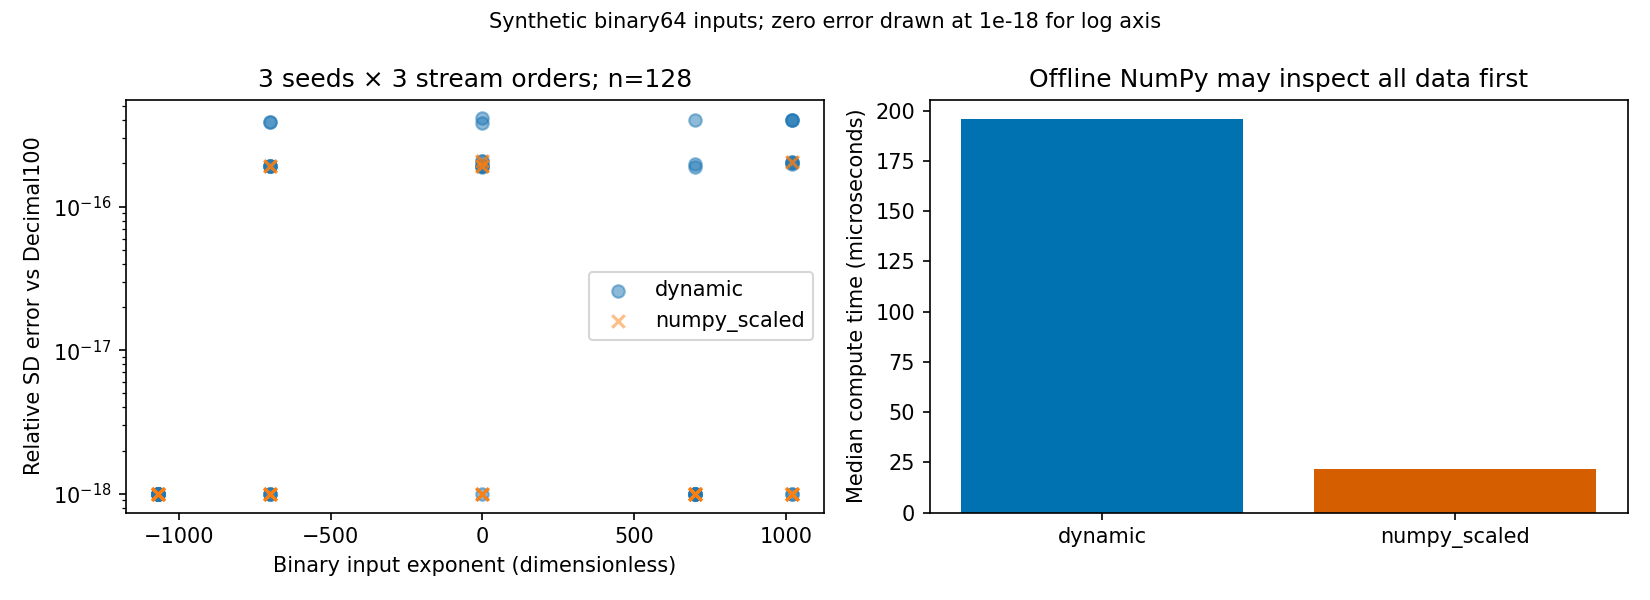

In [5]:
display(Image(filename='results/dynamic_audit.png'))

## Negativos: orden, representación e información
No recuperamos incrementos ya perdidos por binary64. Una escala creciente preserva identidades reales, pero no asociatividad exacta. No hay garantía universal ni merge dinámico. El estado fijo usa memoria constante en número de escalares; medición de memoria es tracemalloc, no RSS.

In [6]:
xs=[1e16+i for i in range(4)]
print('Entradas recibidas:',xs,'SD',dynamic_moments(xs).std)
print('Escala0rechazada:',scaled_moments([1e200,2e200],0))
print('NumPy mediana ns:',summary['median_ns']['numpy_scaled'],'dynamic',summary['median_ns']['dynamic'])
print('Ahora se procesa un generador sin elegir escala a mano; no hay superioridad universal.')

Entradas recibidas: [1e+16, 1e+16, 1.0000000000000002e+16, 1.0000000000000004e+16] SD 1.6583123951777
Escala0rechazada: ScaleResult(n=0, exponent=0, status='normalization_failure', variance=None, std=None)
NumPy mediana ns: 21532.0 dynamic 195744.0
Ahora se procesa un generador sin elegir escala a mano; no hay superioridad universal.


## Fuentes, madurez y siguiente gate
Matriz prior_art_dynamic.md y referencias.bib. Adaptación de ingeniería verificada con datos sintéticos; no operacional, no nueva fórmula estadística. Próximo: merge entre escalas contra oráculo y pruebas adversas antes de exportar API multilenguaje. Gate pendiente: no ocultar pérdidas de rescalado; estudiar compensación frente a coste medido.